# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

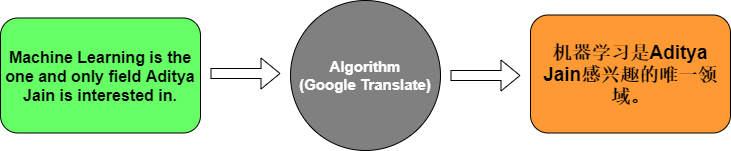

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [1]:
#!pip install tensorflow

In [2]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [3]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [4]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [5]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [6]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.0000e+00 - loss: 2.4862

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.0000e+00 - loss: 2.4862 - val_accuracy: 0.0000e+00 - val_loss: 2.4871


Epoch 2/50


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.5714 - loss: 2.4767

...

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.7143 - loss: 0.6469

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 306ms/step - accuracy: 0.7143 - loss: 0.6469 - val_accuracy: 0.0000e+00 - val_loss: 5.9923


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7143 - loss: 1.8056

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step - accuracy: 0.7143 - loss: 1.8056


Test Accuracy: 0.7142857313156128


In [7]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 832ms/step

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 869ms/step


Input: How are you?
Translation: va va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


**Answers:**

1. **Embedding layer:** it takes the integer index of a word and turns it into a dense vector of real numbers (here 64 values). The vectors are learned during training, so words that are used in similar ways end up with similar vectors. This gives the LSTM a meaningful input instead of a plain ID number.

2. **Encoder LSTM:** it reads the English sentence one word vector at a time and keeps updating its hidden state. After the last word, that final state is a fixed-size summary (context vector) of the whole source sentence. In the example model, `RepeatVector` copies this summary once for every time step of the French output.

3. **Decoder LSTM:** it takes the summary from the encoder and generates the target sentence step by step. With `return_sequences=True` it gives one output vector for every position of the French sentence, and each vector is used to choose the word at that position.

4. **Softmax in the final layer:** for each output position the `Dense` layer gives one score per French word in the vocabulary. Softmax turns those scores into probabilities that are all positive and add up to 1, so we can pick the most likely word with `argmax`, and the model can be trained with `sparse_categorical_crossentropy`.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

### Solution

The example model above only saw three sentences, so it can not translate anything new. For the e-commerce use case we train a real **encoder–decoder (seq2seq) LSTM** on the Kaggle English–French dataset:

- The **encoder** reads the English sentence and passes its final hidden and cell states to the decoder.
- The **decoder** is trained with **teacher forcing**: its input is the French sentence starting with a `sos` (start) token, and its target is the same sentence shifted by one word and ending with an `eos` (end) token.
- At inference time the decoder starts from `sos` and feeds each predicted word back in until it outputs `eos` (greedy decoding).

To keep training time reasonable on a CPU we use short sentences (up to 6 English words and 8 French words) and a sample of 40,000 pairs.

In [8]:
#!pip install kagglehub
import kagglehub
import os
import re
import pandas as pd

# Download the dataset from Kaggle
path = kagglehub.dataset_download("devicharith/language-translation-englishfrench")
print("Files:", os.listdir(path))

df = pd.read_csv(os.path.join(path, "eng_-french.csv"))
df.columns = ["english", "french"]
print("Shape:", df.shape)
df.head()

C:\Users\jaber\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Files: ['eng_-french.csv']


Shape: (175621, 2)


,english,french
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


#### 1. Explore the data

In [9]:
print("Missing values:", df.isna().sum().to_dict())
print("Duplicated pairs:", df.duplicated().sum())
print("English sentences with more than one translation:", df["english"].duplicated().sum())

lengths = pd.DataFrame({
    "english_words": df["english"].str.split().str.len(),
    "french_words": df["french"].str.split().str.len(),
})
lengths.describe()

Missing values: {'english': 0, 'french': 0}


Duplicated pairs: 0
English sentences with more than one translation: 52521


,english_words,french_words
count,175621.000000,175621.000000
mean,6.161552,6.706669
std,2.485664,2.789074
min,1.000000,1.000000
25%,4.000000,5.000000
50%,6.000000,6.000000
75%,7.000000,8.000000
max,44.000000,55.000000


In [10]:
# A few random pairs
df.sample(5, random_state=1)

,english,french
37931,Tom checked the date.,Tom a vérifié la date.
142019,That TV station broadcasts only movies.,Cette chaîne de télévision diffuse uniquement ...
63699,Tell me what I did wrong.,Dites-moi ce que j'ai fait de travers !
37669,They want more space.,Ils veulent plus d'espace.
165392,"If I had more money, I could move to a bigger ...","Si j'avais davantage d'argent, je pourrais dém..."


#### 2. Clean the text

- Lower case everything.
- French uses a narrow no-break space before `?` and `!` (for example `Comment ça va ?`), so we change it to a normal space.
- Remove punctuation but keep apostrophes, because they are part of words like `j'ai` and `I'm`.
- Keep only short sentences, then take a random sample of 40,000 pairs.

In [11]:
def clean_text(text):
    text = text.lower()
    text = text.replace("\u202f", " ").replace("\u00a0", " ").replace("’", "'")
    text = re.sub(r"[^\w\s']", " ", text)  # keep letters (including accents), digits and apostrophes
    return re.sub(r"\s+", " ", text).strip()

df["english"] = df["english"].map(clean_text)
df["french"] = df["french"].map(clean_text)

MAX_ENG_WORDS, MAX_FRN_WORDS, N_PAIRS = 6, 8, 40000
short = df[(df["english"].str.split().str.len() <= MAX_ENG_WORDS) &
           (df["french"].str.split().str.len() <= MAX_FRN_WORDS)]
print("Short pairs available:", len(short))

data = short.sample(N_PAIRS, random_state=42).reset_index(drop=True)

# Decoder input starts with sos, decoder target ends with eos
data["french_in"] = "sos " + data["french"]
data["french_out"] = data["french"] + " eos"
data.head()

Short pairs available: 106074


,english,french,french_in,french_out
0,it wasn't an accident,ce n'était pas un accident,sos ce n'était pas un accident,ce n'était pas un accident eos
1,stop badgering me,arrête de me harceler,sos arrête de me harceler,arrête de me harceler eos
2,this custom dates from ancient times,cette tradition date de temps immémoriaux,sos cette tradition date de temps immémoriaux,cette tradition date de temps immémoriaux eos
3,i could keep it a secret,je pourrais le garder secret,sos je pourrais le garder secret,je pourrais le garder secret eos
4,that's your choice,c'est ton choix,sos c'est ton choix,c'est ton choix eos


#### 3. Tokenize and pad

We keep the 5,000 most common English words and the 7,000 most common French words. Any other word becomes the `<unk>` token. Sequences are padded at the **end** (`padding="post"`) so the real words come first, and the padding (`0`) is masked by the embedding layer.

In [12]:
ENG_VOCAB, FRN_VOCAB = 5000, 7000

tokenizer_en = Tokenizer(num_words=ENG_VOCAB, filters="", oov_token="<unk>")
tokenizer_en.fit_on_texts(data["english"])

tokenizer_fr = Tokenizer(num_words=FRN_VOCAB, filters="", oov_token="<unk>")
tokenizer_fr.fit_on_texts(data["french_in"] + " eos")

print("Unique English words:", len(tokenizer_en.word_index))
print("Unique French words:", len(tokenizer_fr.word_index))

X = pad_sequences(tokenizer_en.texts_to_sequences(data["english"]), padding="post")
Y_in = pad_sequences(tokenizer_fr.texts_to_sequences(data["french_in"]), padding="post")
Y_out = pad_sequences(tokenizer_fr.texts_to_sequences(data["french_out"]), padding="post", maxlen=Y_in.shape[1])

print("English input shape:", X.shape)
print("French decoder input shape:", Y_in.shape)
print("Example:", data["english"][0], "->", X[0], "|", data["french_in"][0], "->", Y_in[0])

Unique English words: 7528
Unique French words: 12674


English input shape: (40000, 6)
French decoder input shape: (40000, 9)
Example: it wasn't an accident -> [  9 178  75 558   0   0] | sos ce n'était pas un accident -> [  2  17 252   6  20 947   0   0   0]


In [13]:
# Train-test split
X_train, X_test, Yin_train, Yin_test, Yout_train, Yout_test, idx_train, idx_test = train_test_split(
    X, Y_in, Y_out, data.index, test_size=0.1, random_state=42)
print("Train:", len(X_train), " Test:", len(X_test))

Train: 36000  Test: 4000


#### 4. Build the encoder–decoder model

In [14]:
tf.keras.utils.set_random_seed(42)
UNITS = 256

# Encoder
encoder_inputs = tf.keras.Input(shape=(None,), name="english")
enc_emb = tf.keras.layers.Embedding(ENG_VOCAB, UNITS, mask_zero=True)(encoder_inputs)
_, state_h, state_c = tf.keras.layers.LSTM(UNITS, return_state=True, name="encoder_lstm")(enc_emb)

# Decoder (starts from the encoder states)
decoder_inputs = tf.keras.Input(shape=(None,), name="french_in")
dec_emb_layer = tf.keras.layers.Embedding(FRN_VOCAB, UNITS, mask_zero=True)
dec_lstm = tf.keras.layers.LSTM(UNITS, return_sequences=True, return_state=True, name="decoder_lstm")
dec_dense = tf.keras.layers.Dense(FRN_VOCAB, activation="softmax")

dec_outputs, _, _ = dec_lstm(dec_emb_layer(decoder_inputs), initial_state=[state_h, state_c])
decoder_outputs = dec_dense(dec_outputs)

nmt_model = tf.keras.Model([encoder_inputs, decoder_inputs], decoder_outputs)
nmt_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
nmt_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ english             │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ french_in           │ (None, None)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, None, 256) │  1,280,000 │ english[0][0]     │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, None)      │          0 │ english[0][0]     │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_2         │ (None, None, 256) │  1,792,000 │ french_in[0][0]   │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_lstm (LSTM) │ [(None, 256),     │    525,312 │ embedding_1[0][0… │
│                     │ (None, 256),      │            │ not_equal[0][0]   │
│                     │ (None, 256)]      │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_lstm (LSTM) │ [(None, None,     │    525,312 │ embedding_2[0][0… │
│                     │ 256), (None,      │            │ encoder_lstm[0][… │
│                     │ 256), (None,      │            │ encoder_lstm[0][… │
│                     │ 256)]             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, None,      │  1,799,000 │ decoder_lstm[0][… │
│                     │ 7000)             │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 5,921,624 (22.59 MB)

 Trainable params: 5,921,624 (22.59 MB)

 Non-trainable params: 0 (0.00 B)

#### 5. Train
Early stopping stops training when the validation loss stops improving and keeps the best weights.

In [15]:
early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)

history = nmt_model.fit(
    [X_train, Yin_train], Yout_train,
    epochs=20, batch_size=128, validation_split=0.1,
    callbacks=[early_stop], verbose=2)

Epoch 1/20


254/254 - 77s - 303ms/step - accuracy: 0.2040 - loss: 5.5327 - val_accuracy: 0.2474 - val_loss: 4.8942


Epoch 2/20


254/254 - 47s - 185ms/step - accuracy: 0.2816 - loss: 4.5296 - val_accuracy: 0.3256 - val_loss: 4.1973


Epoch 3/20


...

254/254 - 35s - 136ms/step - accuracy: 0.8104 - loss: 0.8093 - val_accuracy: 0.5971 - val_loss: 2.1699


Epoch 19/20


254/254 - 35s - 136ms/step - accuracy: 0.8285 - loss: 0.7350 - val_accuracy: 0.6026 - val_loss: 2.1657


Epoch 20/20


254/254 - 35s - 136ms/step - accuracy: 0.8430 - loss: 0.6700 - val_accuracy: 0.6049 - val_loss: 2.1707


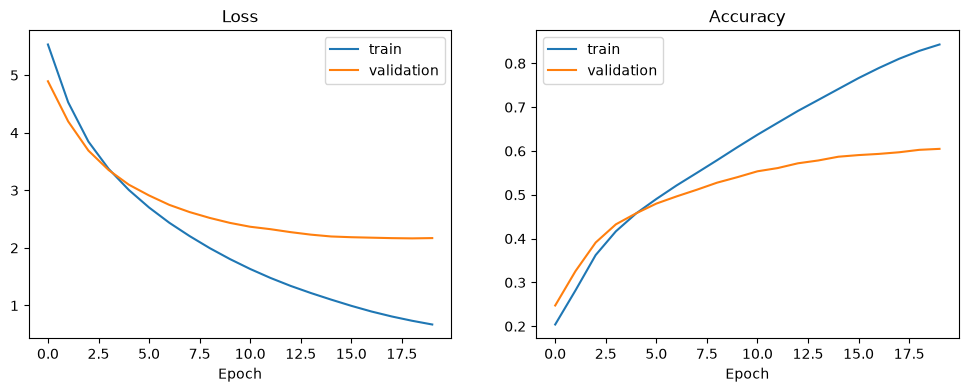

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["loss", "accuracy"]):
    ax.plot(history.history[metric], label="train")
    ax.plot(history.history["val_" + metric], label="validation")
    ax.set_title(metric.capitalize())
    ax.set_xlabel("Epoch")
    ax.legend()
plt.show()

In [17]:
# Evaluate on the test set (accuracy is per word, padding is ignored)
test_loss, test_acc = nmt_model.evaluate([X_test, Yin_test], Yout_test, verbose=0)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

Test Loss: 2.2106
Test Accuracy: 0.5974


#### 6. Inference

For translation we split the trained model into two parts that share its layers:
- the **encoder model** turns an English sentence into the states `h` and `c`,
- the **decoder model** takes one French word plus the states and predicts the next word.

We start every sentence with `sos` and keep adding the most likely word until the model outputs `eos`.

In [18]:
encoder_model = tf.keras.Model(encoder_inputs, [state_h, state_c])

dec_state_h = tf.keras.Input(shape=(UNITS,))
dec_state_c = tf.keras.Input(shape=(UNITS,))
step_outputs, step_h, step_c = dec_lstm(dec_emb_layer(decoder_inputs), initial_state=[dec_state_h, dec_state_c])
decoder_model = tf.keras.Model([decoder_inputs, dec_state_h, dec_state_c], [dec_dense(step_outputs), step_h, step_c])

sos_id = tokenizer_fr.word_index["sos"]
eos_id = tokenizer_fr.word_index["eos"]
index_to_french = {i: w for w, i in tokenizer_fr.word_index.items()}

def translate(sentences, max_len=Y_in.shape[1]):
    # Greedy decoding for a batch of English sentences
    seqs = tokenizer_en.texts_to_sequences([clean_text(s) for s in sentences])
    h, c = encoder_model.predict(pad_sequences(seqs, padding="post"), verbose=0)
    word = np.full((len(sentences), 1), sos_id)
    outputs = []
    for _ in range(max_len):
        probs, h, c = decoder_model.predict([word, h, c], verbose=0)
        word = np.argmax(probs[:, -1, :], axis=-1).reshape(-1, 1)
        outputs.append(word[:, 0])
    results = []
    for ids in np.stack(outputs, axis=1):
        words = []
        for i in ids:
            if i == eos_id:
                break
            words.append(index_to_french.get(i, "<unk>"))
        results.append(" ".join(words))
    return results

print(translate(["How are you?"]))

['comment vous êtes']


In [19]:
# Compare some test sentences with their reference translations
sample = data.loc[idx_test[:15]]
for eng, ref, pred in zip(sample["english"], sample["french"], translate(sample["english"].tolist())):
    print(f"EN:   {eng}\nREF:  {ref}\nPRED: {pred}\n")

EN:   they burned all the documents
REF:  elles ont brûlé tous les documents
PRED: ils ont tous deux

EN:   i gave you fair warning
REF:  je vous ai suffisamment avertis
PRED: je t'ai bien assez averti

EN:   next person please
REF:  personne suivante s'il vous plaît
PRED: la réponse je vous prie

EN:   he employs a maid
REF:  il emploie une femme de ménage
PRED: il emploie une servante

EN:   she's drop dead gorgeous
REF:  elle est bonne à tomber
PRED: elle est morte très morte

EN:   her hair is very short
REF:  elle a les cheveux très courts
PRED: ses cheveux est très attirante

EN:   do you really love me
REF:  m'aimes tu vraiment
PRED: est ce que tu me sens vraiment idiote

EN:   they were wealthy
REF:  ils étaient riches
PRED: elles étaient <unk>

EN:   we're biased
REF:  nous avons des préjugés
PRED: notre chance est à la retraite

EN:   we like tom
REF:  nous aimons bien tom
PRED: nous <unk> tom

EN:   why are you alone
REF:  pourquoi es tu seule
PRED: pourquoi êtes vous seul



#### 7. BLEU score

BLEU compares the predicted words with the reference translation using matching 1- to 4-word n-grams (0 = no overlap, 1 = perfect match). Many English sentences in the dataset have more than one correct French translation, so we use **all** of them as references.

In [20]:
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction

references_by_english = data.groupby("english")["french"].apply(lambda refs: [r.split() for r in refs])

test_eng = data.loc[idx_test[:2000], "english"].tolist()
predictions = translate(test_eng)

references = [references_by_english[e] for e in test_eng]
hypotheses = [p.split() for p in predictions]
bleu = corpus_bleu(references, hypotheses, smoothing_function=SmoothingFunction().method1)
print(f"Corpus BLEU on {len(test_eng)} test sentences: {bleu:.4f}")

Corpus BLEU on 2000 test sentences: 0.2909


#### 8. Use case: translating e-commerce content
Short product and customer-review style sentences:

In [21]:
shop_sentences = [
    "This product is very good.",
    "I love this shirt.",
    "The price is too high.",
    "Where is my order?",
    "This book is cheap.",
    "The shoes are too small.",
    "I want to buy a new car.",
    "Thank you for your help.",
]
for eng, fr in zip(shop_sentences, translate(shop_sentences)):
    print(f"{eng:30} -> {fr}")

This product is very good.     -> ce fait bien est très bon
I love this shirt.             -> j'adore cette chemise
The price is too high.         -> le prix est très <unk>
Where is my order?             -> où est mon métier
This book is cheap.            -> ce livre est passé
The shoes are too small.       -> la femme sont trop
I want to buy a new car.       -> je veux louer une voiture <unk>
Thank you for your help.       -> merci pour ton aide


#### Conclusion

- The encoder–decoder model reached about **60% word accuracy** on the test set (training accuracy 84%) and a **corpus BLEU score of 0.29** on 2,000 test sentences.
- Many translations are correct or close in meaning even when they do not match the reference word for word, for example *"i gave you fair warning"* → *"je t'ai bien assez averti"* and *"he employs a maid"* → *"il emploie une servante"*.
- The gap between training and validation accuracy shows the model starts to **overfit**: with only 40,000 short pairs it memorizes the training data. Rare words become `<unk>` and some sentences lose their meaning (*"where is my order"* → *"où est mon métier"*).
- For a real e-commerce company this model is a good starting point, but it would need much more data, longer sentences, an **attention** mechanism or a Transformer, and product-specific vocabulary. In practice a pre-trained translation model (like the Hugging Face model used in Lab 7) would give much better results.